<a href="https://colab.research.google.com/github/Ag3-S/Neural-Networks-Lab/blob/main/6_Pytorch_completeModel_tuned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Pytorch:1

### Working with data
PyTorch has two primitives to work with data: torch.utils.data.DataLoader and torch.utils.data.Dataset. Dataset stores the samples and their corresponding labels, and DataLoader wraps an iterable around the Dataset.

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

PyTorch offers domain-specific libraries such as TorchText, TorchVision, and TorchAudio, all of which include datasets. For this notebook, we will be using a TorchVision dataset.

The torchvision.datasets module contains Dataset objects for many real-world vision data like CIFAR, COCO (full list here). In this tutorial, we use the FashionMNIST dataset. Every TorchVision Dataset includes two arguments: transform and target_transform to modify the samples and labels respectively.

In [ ]:
# Download training data from open datasets.
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 169kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.23MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.4MB/s]


We pass the Dataset as an argument to DataLoader. This wraps an iterable over our dataset, and supports automatic batching, sampling, shuffling and multiprocess data loading. Here we define a batch size of 64, i.e. each element in the dataloader iterable will return a batch of 64 features and labels.

In [ ]:
batch_size = 64

# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [ ]:
print(training_data.data.shape)
print(test_data.data.shape)

torch.Size([60000, 28, 28])
torch.Size([10000, 28, 28])


## Iterating and Visualizing the Dataset

We can index ``Datasets`` manually like a list: ``training_data[index]``.
We use ``matplotlib`` to visualize some samples in our training data.



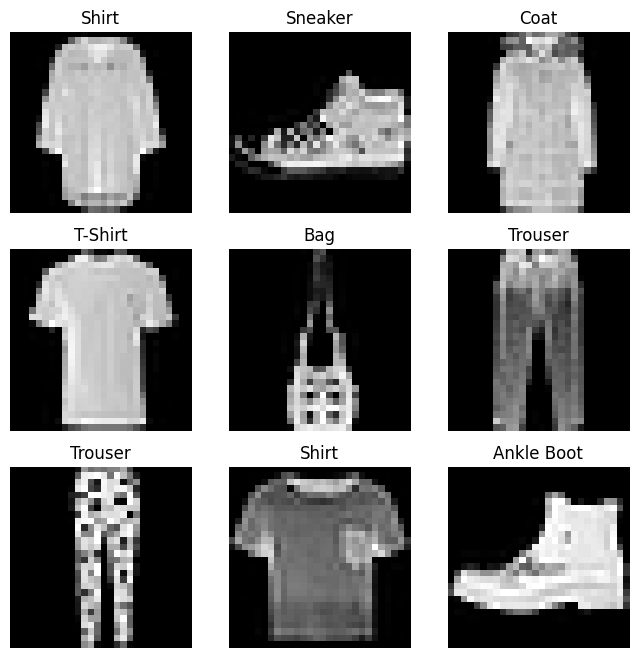

In [ ]:

labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

### Creating Models
To define a neural network in PyTorch, we create a class that inherits from nn.Module. We define the layers of the network in the __init__ function and specify how data will pass through the network in the forward function. To accelerate operations in the neural network, we move it to the GPU or MPS if available.

In [ ]:
# Get cpu, gpu or mps device for training.
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

# Define model
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

Using cuda device
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


### Optimizing the Model Parameters
To train a model, we need a loss function and an optimizer.

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

In a single training loop, the model makes predictions on the training dataset (fed to it in batches), and backpropagates the prediction error to adjust the model’s parameters.

In [ ]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

We also check the model’s performance against the test dataset to ensure it is learning.

In [ ]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

The training process is conducted over several iterations (epochs). During each epoch, the model learns parameters to make better predictions. We print the model’s accuracy and loss at each epoch; we’d like to see the accuracy increase and the loss decrease with every epoch.

In [ ]:
epochs = 5
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.303375  [   64/60000]
loss: 2.288461  [ 6464/60000]
loss: 2.271275  [12864/60000]
loss: 2.267327  [19264/60000]
loss: 2.240290  [25664/60000]
loss: 2.226634  [32064/60000]
loss: 2.225139  [38464/60000]
loss: 2.194615  [44864/60000]
loss: 2.196366  [51264/60000]
loss: 2.166586  [57664/60000]
Test Error: 
 Accuracy: 45.8%, Avg loss: 2.158988 

Epoch 2
-------------------------------
loss: 2.160191  [   64/60000]
loss: 2.158547  [ 6464/60000]
loss: 2.102178  [12864/60000]
loss: 2.131640  [19264/60000]
loss: 2.059829  [25664/60000]
loss: 2.014237  [32064/60000]
loss: 2.038174  [38464/60000]
loss: 1.956554  [44864/60000]
loss: 1.966599  [51264/60000]
loss: 1.907479  [57664/60000]
Test Error: 
 Accuracy: 53.4%, Avg loss: 1.896050 

Epoch 3
-------------------------------
loss: 1.908388  [   64/60000]
loss: 1.892719  [ 6464/60000]
loss: 1.776931  [12864/60000]
loss: 1.838657  [19264/60000]
loss: 1.707180  [25664/60000]
loss: 1.667339  [32064/600

### Saving Models
A common way to save a model is to serialize the internal state dictionary (containing the model parameters).

In [ ]:
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

Saved PyTorch Model State to model.pth


### Loading Models
The process for loading a model includes re-creating the model structure and loading the state dictionary into it.

In [ ]:
model = NeuralNetwork().to(device)
model.load_state_dict(torch.load("model.pth"))

<All keys matched successfully>

This model can now be used to make predictions.

In [ ]:
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

model.eval()
x, y = test_data[10][0], test_data[10][1]
with torch.no_grad():
    x = x.to(device)
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

Predicted: "Coat", Actual: "Coat"


---
# Part 2 — Model-size analysis, hyper-parameter tuning & One-vs-All classification

Everything above this line is the original notebook and is left untouched. Everything below is new.

| Section | What it does |
|---|---|
| **0** | Setup, compute budget, reproducibility helpers |
| **1** | **Size of the final model** (parameters, bytes in memory, bytes on disk, fp16 / int8 variants) |
| **2** | Audit of every hyper-parameter in the original notebook |
| **3** | Fast, leak-free experiment harness (train/val split, GPU-resident data, configurable MLP + CNN) |
| **4** | "Improvement ladder": how much each individual fix is worth |
| **5** | **Systematic hyper-parameter tuning** (staged search + random search + multi-seed confirmation + CNN family) |
| **6** | One single evaluation on the test set, error analysis, saved best model & hyper-parameters |
| **7** | **One-vs-All (OvA) classification**, implemented from scratch, tuned, and compared with softmax |

**Experimental rules used throughout (this is what makes the analysis rigorous):**
1. All tuning is done on a **validation split carved out of the training set**. The original notebook evaluates on the test set after every epoch, so tuning on it would leak information. The test set is touched **only once**, in Section 6 (and once more in Section 7).
2. Every comparison is repeated over **several random seeds**; differences smaller than the seed-to-seed spread are treated as ties.
3. Search proceeds from cheap/coarse to expensive/precise: coarse grid → refined grid → random search → multi-seed, longer-training confirmation of the finalists.

In [ ]:
# =====================================================================
# SECTION 0 — SETUP
# =====================================================================
import os, io, time, copy, json, math, random, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

# `device` is created in an earlier cell of this notebook; fall back if it is missing.
if "device" not in globals():
    device = ("cuda" if torch.cuda.is_available()
              else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

# ---------------------------------------------------------------------
# COMPUTE BUDGET  -> change this one string to scale the whole study.
#   "smoke"    : ~1-3 min   (only checks that the code runs; numbers are meaningless)
#   "quick"    : ~15-30 min (reasonable answers, fewer trials/seeds)         <-- default
#   "standard" : ~1 h+      (more trials, 3-5 seeds, longer final training)
# Times are rough and depend heavily on your hardware (GPU/MPS >> CPU, esp. for the CNN).
# ---------------------------------------------------------------------
BUDGET = "quick"
BUDGETS = {
    #            coarse  rs     final   #random  #seeds  #cnn    #seeds   ova    OvA-final
    #            epochs  epochs epochs  trials   (conf.) trials  (final)  epochs seeds
    "smoke":    dict(coarse_ep=1,  rs_ep=1,  final_ep=2,  n_rs=3,  n_seeds=2, n_cnn=2,  final_seeds=2, ova_ep=1,  ova_seeds=1),
    "quick":    dict(coarse_ep=6,  rs_ep=8,  final_ep=15, n_rs=14, n_seeds=2, n_cnn=6,  final_seeds=3, ova_ep=6,  ova_seeds=2),
    "standard": dict(coarse_ep=10, rs_ep=12, final_ep=30, n_rs=30, n_seeds=3, n_cnn=12, final_seeds=5, ova_ep=12, ova_seeds=3),
}
B = BUDGETS[BUDGET]
print("Budget:", BUDGET, B)

SEED = 42
def set_seed(s):
    """Seed python, numpy and torch (CPU + the active accelerator) for reproducibility."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

_t0 = time.time()
def elapsed(msg=""):
    print(f"[{(time.time()-_t0)/60:6.1f} min elapsed] {msg}")

LOG = []   # every training run in Sections 4-5 is appended here (saved to CSV at the end)

Using device: cuda
Budget: quick {'coarse_ep': 6, 'rs_ep': 8, 'final_ep': 15, 'n_rs': 14, 'n_seeds': 2, 'n_cnn': 6, 'final_seeds': 3, 'ova_ep': 6, 'ova_seeds': 2}


## 1. Size of the final model

The "final model" of the original notebook is `NeuralNetwork`: `784 → 512 → 512 → 10` with ReLUs.

**By hand** (a `Linear(in, out)` layer has `in·out` weights + `out` biases):

| Layer | Weights | Biases | Total |
|---|---:|---:|---:|
| `Linear(784, 512)` | 401,408 | 512 | 401,920 |
| `Linear(512, 512)` | 262,144 | 512 | 262,656 |
| `Linear(512, 10)`  | 5,120 | 10 | 5,130 |
| **Total** | | | **669,706 parameters** |

Stored as float32 (4 bytes each) that is `669,706 × 4 = 2,678,824 bytes ≈ 2.68 MB ≈ 2.55 MiB`.
ReLU and Flatten have no parameters. The code below verifies this and measures the real `model.pth` size
(which is slightly larger than the raw tensors because of pickle/zip metadata and tensor names).

In [ ]:
# =====================================================================
# SECTION 1 — SIZE OF THE FINAL MODEL
# =====================================================================
def size_report(m, name="model", per_layer=False):
    """Parameter count and storage size of any nn.Module."""
    n_params   = sum(p.numel() for p in m.parameters())
    n_train    = sum(p.numel() for p in m.parameters() if p.requires_grad)
    p_bytes    = sum(p.numel() * p.element_size() for p in m.parameters())
    b_bytes    = sum(b.numel() * b.element_size() for b in m.buffers())   # e.g. BatchNorm running stats
    buf = io.BytesIO(); torch.save(m.state_dict(), buf)                   # what torch.save(state_dict) writes
    file_bytes = buf.getbuffer().nbytes
    if per_layer:
        rows = [dict(tensor=n, shape=tuple(p.shape), params=p.numel(), bytes_fp32=p.numel()*p.element_size())
                for n, p in m.named_parameters()]
        display(pd.DataFrame(rows))
    return dict(model=name, params=n_params, trainable=n_train,
                tensor_bytes=p_bytes + b_bytes, tensor_MiB=(p_bytes + b_bytes) / 2**20,
                state_dict_MB=file_bytes / 1e6)

# the trained model from the original notebook (falls back to a fresh one if the cell was not run)
baseline_model = model if "model" in globals() else NeuralNetwork()
rep = size_report(baseline_model, "baseline MLP 784-512-512-10", per_layer=True)
print(json.dumps(rep, indent=2))
assert rep["params"] == 669_706, "unexpected parameter count"
print(f"\n=> {rep['params']:,} parameters = {rep['tensor_bytes']:,} bytes "
      f"= {rep['tensor_MiB']:.2f} MiB (float32).  state_dict serialised: {rep['state_dict_MB']:.3f} MB")
if os.path.exists("model.pth"):
    print(f"model.pth on disk: {os.path.getsize('model.pth')/1e6:.3f} MB")

# ---- how much smaller can it get? (storage formats) -------------------
def state_bytes(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.getbuffer().nbytes

rows = [("float32 (as trained)", state_bytes(baseline_model))]
rows.append(("float16 (half precision)", state_bytes(copy.deepcopy(baseline_model).cpu().half())))
try:  # dynamic int8 quantisation of the Linear layers (CPU only)
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # PyTorch prints deprecation notices for this API; harmless here
        q = torch.ao.quantization.quantize_dynamic(copy.deepcopy(baseline_model).cpu().eval(), {nn.Linear}, dtype=torch.qint8)
    rows.append(("int8 (dynamic quantisation)", state_bytes(q)))
except Exception as e:
    print("int8 quantisation skipped on this platform:", repr(e)[:120])
sz = pd.DataFrame(rows, columns=["format", "bytes"])
sz["MB"] = (sz.bytes / 1e6).round(3)
sz["vs_fp32"] = (sz.bytes / sz.bytes.iloc[0]).round(2)
display(sz)

,tensor,shape,params,bytes_fp32
0,linear_relu_stack.0.weight,"(512, 784)",401408,1605632
1,linear_relu_stack.0.bias,"(512,)",512,2048
2,linear_relu_stack.2.weight,"(512, 512)",262144,1048576
3,linear_relu_stack.2.bias,"(512,)",512,2048
4,linear_relu_stack.4.weight,"(10, 512)",5120,20480
5,linear_relu_stack.4.bias,"(10,)",10,40


{
  "model": "baseline MLP 784-512-512-10",
  "params": 669706,
  "trainable": 669706,
  "tensor_bytes": 2678824,
  "tensor_MiB": 2.5547256469726562,
  "state_dict_MB": 2.681813
}

=> 669,706 parameters = 2,678,824 bytes = 2.55 MiB (float32).  state_dict serialised: 2.682 MB
model.pth on disk: 2.682 MB


,format,bytes,MB,vs_fp32
0,float32 (as trained),2681813,2.682,1.00
1,float16 (half precision),1342357,1.342,0.50
2,int8 (dynamic quantisation),677887,0.678,0.25


## 2. Audit of the original notebook's (hyper-)parameters

| Item | Original value | Observation |
|---|---|---|
| Model | MLP 784-512-512-10, ReLU, no dropout / batch-norm | 669,706 params. Flattening throws away the 2-D structure of the image, which caps MLP accuracy; a small CNN usually does clearly better with *fewer* parameters. |
| Optimizer | plain SGD, **lr = 1e-3, momentum = 0** | Very small steps. The notebook's own saved output reaches 71.2 % after 5 epochs and is *still* climbing (83.0 % after the 50 epochs logged in the output) → the model is **under-trained**, not over-fitted. |
| Epochs | 5 (the saved output contains 50 epoch logs, so the cell was presumably re-run) | Far too short for lr = 1e-3 SGD. |
| Batch size | 64 | Fine, but interacts strongly with the learning rate (Section 5, stage 2). |
| Shuffling | `DataLoader(train, batch_size)` → **no `shuffle=True`** | The same batch sequence every epoch; standard practice is to reshuffle. |
| Input scaling | `ToTensor()` only → pixels in [0, 1] (mean ≈ 0.29) | Not zero-centred; standardising makes optimisation better conditioned. |
| Evaluation | test set evaluated after every epoch; no validation set | Any tuning against this would **leak the test set**. We use a train/validation split. |
| Regularisation / LR schedule / early stopping | none | Candidates for tuning. |
| Seed | none | Results change from run to run, so single-run differences of a few tenths of a percent are noise. |
| Loss | `CrossEntropyLoss` on logits | Correct. |

Statistical note for the experiments below: with a 10,000-image validation set an accuracy near 90 % has a binomial
standard error of about `sqrt(0.9·0.1/10000) ≈ 0.3 %`. Differences of a few tenths of a percent between two configurations
are therefore **not** meaningful unless they are consistent across seeds.

## 3. Experiment harness

To run hundreds of training runs in a reasonable time we keep the whole dataset **on the accelerator as tensors**
(FashionMNIST is only ~190 MB as float32) and do our own batching, instead of using the `DataLoader`. This removes the
data-loading overhead. The harness provides:

* a **50k / 10k train / validation split** (fixed seed) plus the untouched 10k test set,
* a configurable `MLP` (width, depth, dropout, batch-norm, activation) and a small `CNN`,
* optimizers `sgd`, `sgd_mom` (Nesterov momentum 0.9), `adam`, `adamw`,
* per-step LR schedules (`none`, `cosine`, `onecycle`),
* optional on-GPU augmentation (random horizontal flip, random translation),
* `fit(cfg, data, epochs, seed)` → returns final / best validation accuracy and the training history.

In [ ]:
# =====================================================================
# SECTION 3 — DATA, MODELS, TRAINING HARNESS
# =====================================================================
# ---- data as tensors in [0,1], shape [N,1,28,28] ---------------------
X_all  = training_data.data.float().div(255.0).unsqueeze(1)
y_all  = training_data.targets.clone().long()
X_test = test_data.data.float().div(255.0).unsqueeze(1)
y_test = test_data.targets.clone().long()

# ---- fixed train / validation split (never touches the test set) ------
N_ALL = len(y_all); N_VAL = N_ALL // 6                       # 10,000 for the real dataset
_perm = torch.randperm(N_ALL, generator=torch.Generator().manual_seed(SEED))
val_idx, tr_idx = _perm[:N_VAL], _perm[N_VAL:]
X_tr, y_tr, X_val, y_val = X_all[tr_idx], y_all[tr_idx], X_all[val_idx], y_all[val_idx]

# ---- normalisation statistics computed on the *training part only* ----
FM_MEAN, FM_STD = X_tr.mean().item(), X_tr.std().item()
print(f"train {tuple(X_tr.shape)}  val {tuple(X_val.shape)}  test {tuple(X_test.shape)}")
print(f"pixel mean {FM_MEAN:.4f}  std {FM_STD:.4f}")
print("val class counts :", torch.bincount(y_val, minlength=10).tolist())

# move everything to the accelerator once
X_tr, y_tr, X_val, y_val = [t.to(device) for t in (X_tr, y_tr, X_val, y_val)]
X_all, y_all, X_test, y_test = [t.to(device) for t in (X_all, y_all, X_test, y_test)]
DATA_TV   = (X_tr,  y_tr,  X_val,  y_val)      # used for ALL tuning
DATA_TEST = (X_all, y_all, X_test, y_test)     # train on full 60k, evaluate on test: used ONLY for final numbers

def prep(x, normalize=True):
    return (x - FM_MEAN) / FM_STD if normalize else x

def iterate_batches(X, y, bs, shuffle=True):
    """Yield mini-batches from tensors already on the device."""
    n = X.shape[0]
    idx = (torch.randperm(n) if shuffle else torch.arange(n)).to(X.device)
    for i in range(0, n, bs):
        sel = idx[i:i + bs]
        if len(sel) < 2:            # BatchNorm cannot handle a batch of one sample
            continue
        yield X[sel], y[sel]

def augment(xb, flip=False, shift=0):
    """GPU augmentation on raw [0,1] images: per-sample horizontal flip and per-sample random translation (zero padded)."""
    if flip:
        m = torch.rand(xb.shape[0], device=xb.device) < 0.5
        xb = torch.where(m[:, None, None, None], xb.flip(-1), xb)
    if shift > 0:
        Bn, C, H, W = xb.shape
        padded = F.pad(xb, (shift, shift, shift, shift))
        dy = torch.randint(0, 2 * shift + 1, (Bn,), device=xb.device)
        dx = torch.randint(0, 2 * shift + 1, (Bn,), device=xb.device)
        iy = torch.arange(H, device=xb.device)[None, :] + dy[:, None]
        ix = torch.arange(W, device=xb.device)[None, :] + dx[:, None]
        bi = torch.arange(Bn, device=xb.device)[:, None, None]
        xb = padded[bi, :, iy[:, :, None], ix[:, None, :]].permute(0, 3, 1, 2).contiguous()
    return xb

# ---- models -----------------------------------------------------------
ACTS = {"relu": nn.ReLU, "gelu": nn.GELU, "silu": nn.SiLU}

class MLP(nn.Module):
    """Configurable MLP. hidden=(512,512) reproduces the original network. hidden=() is a linear classifier."""
    def __init__(self, hidden=(512, 512), dropout=0.0, batchnorm=False, activation="relu", in_dim=784, out_dim=10):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(ACTS[activation]())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    """Small VGG-style CNN: [conv3x3 -> (BN) -> act -> maxpool] x len(channels), then a one-hidden-layer classifier."""
    def __init__(self, channels=(32, 64), fc=128, dropout=0.3, batchnorm=True, activation="relu", out_dim=10):
        super().__init__()
        layers, c_in, size = [], 1, 28
        for c in channels:
            layers.append(nn.Conv2d(c_in, c, 3, padding=1))
            if batchnorm: layers.append(nn.BatchNorm2d(c))
            layers += [ACTS[activation](), nn.MaxPool2d(2)]
            c_in, size = c, size // 2
        layers += [nn.Flatten(), nn.Linear(c_in * size * size, fc)]
        if batchnorm: layers.append(nn.BatchNorm1d(fc))
        layers.append(ACTS[activation]())
        if dropout > 0: layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(fc, out_dim))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

# ---- hyper-parameter configuration -----------------------------------
DEFAULTS = dict(arch="mlp", hidden=(512, 512), channels=(32, 64), fc=128,
                dropout=0.0, batchnorm=False, activation="relu",
                optimizer="adam", lr=1e-3, momentum=0.9, weight_decay=0.0, scheduler="none",
                batch_size=128, shuffle=True, normalize=True, flip=False, shift=0, label_smoothing=0.0)
def make_cfg(**kw):
    unknown = set(kw) - set(DEFAULTS)
    assert not unknown, f"unknown hyper-parameters: {unknown}"
    return {**DEFAULTS, **kw}

# the original notebook, expressed in this framework
BASELINE = make_cfg(optimizer="sgd", lr=1e-3, batch_size=64, shuffle=False, normalize=False)

def build_model(cfg, out_dim=10):
    if cfg["arch"] == "mlp":
        return MLP(cfg["hidden"], cfg["dropout"], cfg["batchnorm"], cfg["activation"], out_dim=out_dim)
    return CNN(cfg["channels"], cfg["fc"], cfg["dropout"], cfg["batchnorm"], cfg["activation"], out_dim=out_dim)

def make_optimizer(params, cfg):
    o, lr, wd = cfg["optimizer"], cfg["lr"], cfg["weight_decay"]
    if o == "sgd":     return torch.optim.SGD(params, lr=lr, weight_decay=wd)
    if o == "sgd_mom": return torch.optim.SGD(params, lr=lr, momentum=cfg["momentum"], nesterov=True, weight_decay=wd)
    if o == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if o == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(o)

def make_scheduler(opt, cfg, steps_per_epoch, epochs):
    """LR schedules are stepped once per batch."""
    s, total = cfg["scheduler"], steps_per_epoch * epochs
    if s == "none":     return None
    if s == "cosine":   return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total, eta_min=cfg["lr"] * 0.01)
    if s == "onecycle": return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=total, pct_start=0.2,
                                                                  cycle_momentum=(cfg["optimizer"] != "sgd"))
    raise ValueError(s)

@torch.no_grad()
def predict_logits(m, X, normalize=True, bs=5000):
    m.eval()
    return torch.cat([m(prep(X[i:i + bs], normalize)) for i in range(0, X.shape[0], bs)])

def evaluate(m, X, y, normalize=True):
    """(cross-entropy loss, accuracy) of a softmax-style model."""
    lg = predict_logits(m, X, normalize)
    return F.cross_entropy(lg, y).item(), (lg.argmax(1) == y).float().mean().item()

def fit(cfg, data, epochs, seed=0, return_model=False, verbose=False):
    """
    Train one model.  data = (X_train, y_train, X_eval, y_eval).
    'eval' is the VALIDATION set during tuning and the TEST set only in the final runs.
    Returns a dict with final-epoch and best-epoch accuracy and the per-epoch history.
    We rank configurations by *final-epoch* accuracy (picking the best epoch on the eval set would be optimistic).
    """
    Xtr, ytr, Xev, yev = data
    set_seed(seed)
    m = build_model(cfg).to(device)
    opt = make_optimizer(m.parameters(), cfg)
    spe = math.ceil(len(ytr) / cfg["batch_size"])
    sch = make_scheduler(opt, cfg, spe, epochs)
    hist, t0, diverged = [], time.time(), False
    for ep in range(epochs):
        m.train(); run, seen = 0.0, 0
        for xb, yb in iterate_batches(Xtr, ytr, cfg["batch_size"], cfg["shuffle"]):
            xb = prep(augment(xb, cfg["flip"], cfg["shift"]), cfg["normalize"])
            loss = F.cross_entropy(m(xb), yb, label_smoothing=cfg["label_smoothing"])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if sch is not None: sch.step()
            run += loss.detach() * len(yb); seen += len(yb)
        tr_loss = (run / seen).item()
        if not math.isfinite(tr_loss):               # diverged (lr too high) -> stop, count as chance level
            diverged = True; break
        ev_loss, ev_acc = evaluate(m, Xev, yev, cfg["normalize"])
        hist.append(dict(epoch=ep + 1, train_loss=tr_loss, eval_loss=ev_loss, eval_acc=ev_acc))
        if verbose: print(f"  epoch {ep+1:3d}  train_loss {tr_loss:.4f}  eval_loss {ev_loss:.4f}  eval_acc {ev_acc*100:.2f}%")
    h = pd.DataFrame(hist)
    out = dict(final_acc=0.1 if diverged or h.empty else h.eval_acc.iloc[-1],
               best_acc=0.1 if diverged or h.empty else h.eval_acc.max(),
               best_epoch=0 if h.empty else int(h.eval_acc.idxmax()) + 1,
               final_train_loss=float("nan") if h.empty else h.train_loss.iloc[-1],
               final_eval_loss=float("nan") if h.empty else h.eval_loss.iloc[-1],
               diverged=diverged, seconds=time.time() - t0,
               params=sum(p.numel() for p in m.parameters()), history=h)
    if return_model: out["model"] = m
    return out

def flat(cfg):
    """Flatten a config for logging into a DataFrame."""
    d = dict(cfg)
    d["hidden"] = "-".join(map(str, d["hidden"])) if d["arch"] == "mlp" else ""
    d["channels"] = "-".join(map(str, d["channels"])) if d["arch"] == "cnn" else ""
    return d

def run_cfg(cfg, epochs, seeds, stage, data=None):
    """Run one config over several seeds, log everything, return (mean, std, per-seed accuracies)."""
    data = DATA_TV if data is None else data
    accs = []
    for s in seeds:
        r = fit(cfg, data, epochs, seed=s)
        accs.append(r["final_acc"])
        LOG.append(dict(stage=stage, epochs=epochs, seed=s, final_acc=r["final_acc"], best_acc=r["best_acc"],
                        seconds=r["seconds"], params=r["params"], **flat(cfg)))
    return float(np.mean(accs)), float(np.std(accs)), accs

SEEDS        = list(range(B["n_seeds"]))      # seeds for confirmation runs
SEEDS_COARSE = [0]                            # coarse sweeps use a single seed to save time

# ---- smoke test of the harness + timing of one epoch -------------------
r = fit(BASELINE, DATA_TV, 1, seed=0)
print(f"baseline, 1 epoch: val acc {r['final_acc']*100:.2f}%  ({r['seconds']:.1f}s/epoch for the MLP)")
r = fit(make_cfg(arch="cnn", dropout=0.3, batchnorm=True), DATA_TV, 1, seed=0)
print(f"small CNN, 1 epoch: val acc {r['final_acc']*100:.2f}%  ({r['seconds']:.1f}s/epoch for the CNN, {r['params']:,} params)")

train (50000, 1, 28, 28)  val (10000, 1, 28, 28)  test (10000, 1, 28, 28)
pixel mean 0.2859  std 0.3529
val class counts : [980, 979, 1061, 974, 1046, 1055, 984, 993, 957, 971]
baseline, 1 epoch: val acc 45.91%  (1.1s/epoch for the MLP)
small CNN, 1 epoch: val acc 90.18%  (4.8s/epoch for the CNN, 422,090 params)


## 4. How can accuracy be improved? — the "improvement ladder"

Before tuning anything, we measure how much each *individual, well-known* fix is worth. Starting from the notebook's
exact configuration we apply the changes **cumulatively** (each row keeps all earlier changes) and record the validation accuracy over several seeds.

Why each change should help:

* **Shuffle** — removes the fixed batch order, so gradient noise is unbiased across epochs.
* **Normalise inputs** — zero-mean / unit-variance inputs give a better-conditioned loss surface, so larger learning rates are stable.
* **Momentum (Nesterov)** — averages gradients across steps; with lr = 1e-3 plain SGD barely moves, momentum 0.9 gives ~10× the effective step.
* **Train longer** — the original run was still improving after 50 epochs.
* **Cosine LR schedule** — big steps early, tiny steps at the end, which reduces final-epoch noise.
* **Dropout** — regularisation; only useful once the model starts to over-fit.
* **CNN (+ batch-norm)** — convolutions exploit spatial structure (local patterns, translation equivariance) that an MLP cannot.

Rows marked `≈ noise` changed accuracy by less than the seed-to-seed spread / validation standard error (~0.3 %).

0  baseline (original notebook)                63.39% ± 0.07
1  + shuffle training data                     64.51% ± 0.03
2  + normalise inputs                          75.91% ± 0.01
3  + SGD+momentum (lr 0.01), batch 128         88.21% ± 0.15
4  + train longer                              88.94% ± 0.12
5  + cosine LR schedule                        88.60% ± 0.04
6  + dropout 0.2                               88.48% ± 0.02
7  + CNN with batch-norm, dropout 0.3          92.73% ± 0.06


,step,epochs,val_acc_pct,std_pct,delta_pct,verdict
0,0 baseline (original notebook),5,63.39,0.07,NaN,NaN
1,1 + shuffle training data,5,64.51,0.03,1.12,better
2,2 + normalise inputs,5,75.91,0.01,11.40,better
3,"3 + SGD+momentum (lr 0.01), batch 128",5,88.21,0.15,12.30,better
4,4 + train longer,8,88.94,0.12,0.73,better
5,5 + cosine LR schedule,8,88.60,0.04,-0.35,WORSE
6,6 + dropout 0.2,8,88.48,0.02,-0.12,≈ noise
7,"7 + CNN with batch-norm, dropout 0.3",8,92.73,0.06,4.25,better


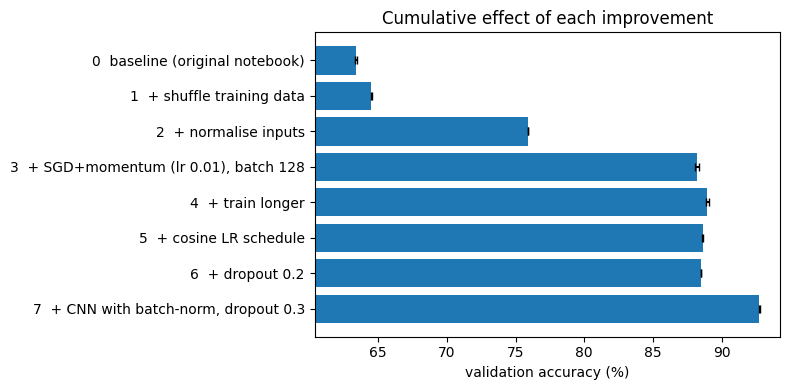

[   1.6 min elapsed] ladder done


In [ ]:
# =====================================================================
# SECTION 4 — IMPROVEMENT LADDER (cumulative changes over several seeds)
# =====================================================================
L = B["rs_ep"]
ladder_steps = [
    ("0  baseline (original notebook)",              {},                                                    5),
    ("1  + shuffle training data",                   dict(shuffle=True),                                    5),
    ("2  + normalise inputs",                        dict(normalize=True),                                  5),
    ("3  + SGD+momentum (lr 0.01), batch 128",       dict(optimizer="sgd_mom", lr=0.01, batch_size=128),    5),
    ("4  + train longer",                            {},                                                    L),
    ("5  + cosine LR schedule",                      dict(scheduler="cosine"),                              L),
    ("6  + dropout 0.2",                             dict(dropout=0.2),                                     L),
    ("7  + CNN with batch-norm, dropout 0.3",        dict(arch="cnn", dropout=0.3, batchnorm=True),         L),
]
cfg, rows, prev = dict(BASELINE), [], None
for name, delta, ep in ladder_steps:
    cfg = {**cfg, **delta}
    mean, std, accs = run_cfg(cfg, ep, SEEDS, "ladder")
    row = dict(step=name, epochs=ep, val_acc_pct=round(mean * 100, 2), std_pct=round(std * 100, 2))
    if prev is not None:
        d = (mean - prev[0]) * 100
        row["delta_pct"] = round(d, 2)
        row["verdict"] = "≈ noise" if abs(d) < max(0.3, 2 * np.hypot(std, prev[1]) * 100) else ("better" if d > 0 else "WORSE")
    rows.append(row); prev = (mean, std)
    print(f"{name:45s} {mean*100:6.2f}% ± {std*100:.2f}")
df_ladder = pd.DataFrame(rows)
display(df_ladder)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(df_ladder.step[::-1], df_ladder.val_acc_pct[::-1], xerr=df_ladder.std_pct[::-1], capsize=3)
ax.set_xlim(max(0, df_ladder.val_acc_pct.min() - 3), min(100, df_ladder.val_acc_pct.max() + 1.5))
ax.set_xlabel("validation accuracy (%)"); ax.set_title("Cumulative effect of each improvement"); plt.tight_layout(); plt.show()
elapsed("ladder done")

## 5. Systematic hyper-parameter tuning

Grid search over everything is exponentially expensive, and pure random search ignores what we already know
about how hyper-parameters interact. We therefore use a **staged** procedure (coordinate descent on the most important
hyper-parameters, then random search on the rest, then confirmation):

| Stage | Search | Why this order |
|---|---|---|
| 1 | **optimizer × learning rate** (log-spaced grid) | The learning rate is almost always the most important hyper-parameter; its best value depends on the optimizer. |
| 2 | **batch size × learning-rate multiplier** (2-D grid) | Batch size and learning rate are coupled (bigger batch → less noisy gradient → can use a larger lr), so they must be tuned *jointly*. |
| 3 | **Random search** over width/depth, dropout, batch-norm, activation, weight decay, LR schedule, label smoothing, and a ±0.3-decade lr jitter | Many weakly-important parameters: random search covers the important ones more densely than a grid (Bergstra & Bengio, 2012). |
| 4 | **Confirmation**: the top-K random-search configs re-trained with multiple seeds and for longer | A single short run is noisy and "winner's-curse" biased; this picks the config that is *reliably* best. |
| 5 | **CNN family**: random search over channels, fc size, dropout, BN, optimizer, lr, schedule, augmentation, batch size, then the same confirmation | The MLP family has a ceiling; we check whether a CNN is worth it. |

All stages use the 50k/10k train/validation split and rank configurations by **final-epoch** validation accuracy.

  sgd      lr=0.03    ->  85.84%
  sgd      lr=0.1     ->  87.97%
  sgd      lr=0.3     ->  89.35%
  sgd_mom  lr=0.003   ->  85.83%
  sgd_mom  lr=0.01    ->  88.00%
  sgd_mom  lr=0.03    ->  89.58%
  sgd_mom  lr=0.1     ->  89.96%
  adam     lr=0.0003  ->  88.81%
  adam     lr=0.001   ->  89.81%
  adam     lr=0.003   ->  89.69%
  adamw    lr=0.0003  ->  88.75%
  adamw    lr=0.001   ->  89.78%
  adamw    lr=0.003   ->  89.62%


,optimizer,lr,val_acc
0,sgd_mom,0.1000,89.96
1,adam,0.0010,89.81
2,adamw,0.0010,89.78
3,adam,0.0030,89.69
4,adamw,0.0030,89.62
5,sgd_mom,0.0300,89.58
6,sgd,0.3000,89.35
7,adam,0.0003,88.81


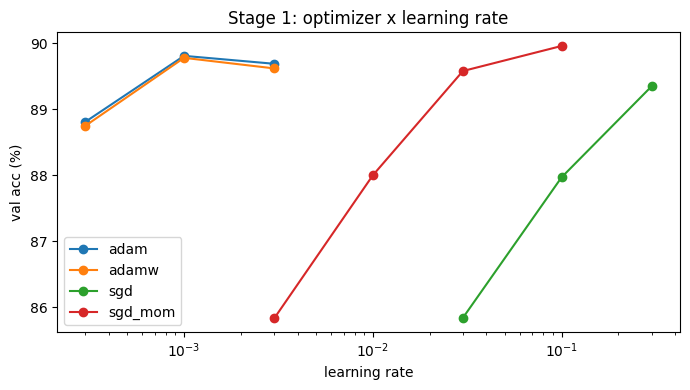

best lr per optimizer: {'adam': np.float64(0.001), 'adamw': np.float64(0.001), 'sgd': np.float64(0.3), 'sgd_mom': np.float64(0.1)}
==> stage-1 winner: sgd_mom, lr=0.1
[   2.4 min elapsed] stage 1 done


In [ ]:
# =====================================================================
# STAGE 1 — optimizer x learning rate (coarse grid, MLP 512-512)
# =====================================================================
grid1 = [("sgd",     [0.03, 0.1, 0.3]),            # plain SGD needs much larger lr than the notebook's 1e-3
         ("sgd_mom", [0.003, 0.01, 0.03, 0.1]),
         ("adam",    [3e-4, 1e-3, 3e-3]),
         ("adamw",   [3e-4, 1e-3, 3e-3])]
s1 = []
for opt_name, lrs in grid1:
    for lr in lrs:
        cfg = make_cfg(optimizer=opt_name, lr=lr, scheduler="cosine", weight_decay=0.01 if opt_name == "adamw" else 0.0)
        mean, std, _ = run_cfg(cfg, B["coarse_ep"], SEEDS_COARSE, "stage1")
        s1.append(dict(optimizer=opt_name, lr=lr, val_acc=mean))
        print(f"  {opt_name:8s} lr={lr:<7g} -> {mean*100:6.2f}%")
df1 = pd.DataFrame(s1).sort_values("val_acc", ascending=False).reset_index(drop=True)
display(df1.assign(val_acc=(df1.val_acc * 100).round(2)).head(8))

fig, ax = plt.subplots(figsize=(7, 4))
for name, g in df1.groupby("optimizer"):
    g = g.sort_values("lr"); ax.plot(g.lr, g.val_acc * 100, "o-", label=name)
ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel("val acc (%)"); ax.legend()
ax.set_title("Stage 1: optimizer x learning rate"); plt.tight_layout(); plt.show()

best_lr_by_opt = {o: g.sort_values("val_acc").iloc[-1].lr for o, g in df1.groupby("optimizer")}
BEST_OPT, S1_LR = df1.iloc[0].optimizer, float(df1.iloc[0].lr)
print("best lr per optimizer:", best_lr_by_opt)
print(f"==> stage-1 winner: {BEST_OPT}, lr={S1_LR}")
elapsed("stage 1 done")

lr_mult,0.5,1.0,2.0
batch_size,,,
64,89.81,89.30,10.00
128,89.82,89.96,89.31
256,89.30,89.76,89.28
512,88.36,89.20,89.16


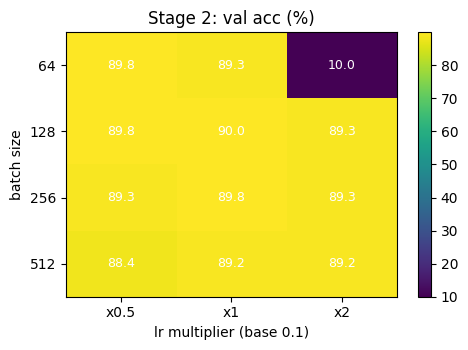

==> stage-2 winner: batch_size=128, lr=0.1
[   2.9 min elapsed] stage 2 done


In [ ]:
# =====================================================================
# STAGE 2 — batch size x learning-rate multiplier (jointly, for the stage-1 winner)
# =====================================================================
bs_list, mults = [64, 128, 256, 512], [0.5, 1.0, 2.0]
s2 = []
for bs in bs_list:
    for mu in mults:
        cfg = make_cfg(optimizer=BEST_OPT, lr=S1_LR * mu, batch_size=bs, scheduler="cosine",
                       weight_decay=0.01 if BEST_OPT == "adamw" else 0.0)
        mean, std, _ = run_cfg(cfg, B["coarse_ep"], SEEDS_COARSE, "stage2")
        s2.append(dict(batch_size=bs, lr_mult=mu, lr=S1_LR * mu, val_acc=mean))
df2 = pd.DataFrame(s2)
piv = df2.pivot(index="batch_size", columns="lr_mult", values="val_acc") * 100
display(piv.round(2))

fig, ax = plt.subplots(figsize=(5, 3.6))
im = ax.imshow(piv.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"x{c:g}" for c in piv.columns])
ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]): ax.text(j, i, f"{piv.values[i, j]:.1f}", ha="center", va="center", color="w", fontsize=9)
ax.set_xlabel(f"lr multiplier (base {S1_LR:g})"); ax.set_ylabel("batch size"); ax.set_title("Stage 2: val acc (%)")
plt.colorbar(im); plt.tight_layout(); plt.show()

b2 = df2.sort_values("val_acc", ascending=False).iloc[0]
S2_BS, S2_LR = int(b2.batch_size), float(b2.lr)
print(f"==> stage-2 winner: batch_size={S2_BS}, lr={S2_LR:.5g}")
elapsed("stage 2 done")

In [ ]:
# =====================================================================
# STAGE 3 — random search over architecture / regularisation / schedule (MLP family)
# =====================================================================
rng = np.random.default_rng(SEED)
HIDDEN_CHOICES = [(256, 256), (512, 512), (1024, 512), (1024, 1024), (512, 512, 512), (1024, 512, 256)]
def pick(r, lst): return lst[int(r.integers(len(lst)))]

def wd_sample(r, opt_name):
    """Decoupled weight decay (AdamW) lives on a much larger scale than classic L2 weight decay."""
    if opt_name == "adamw": return float(10 ** r.uniform(-3, -1))
    return 0.0 if r.random() < 0.3 else float(10 ** r.uniform(-6, -3.5))

def sample_mlp_cfg(r):
    return make_cfg(optimizer=BEST_OPT, batch_size=S2_BS,
                    lr=float(S2_LR * 10 ** r.uniform(-0.3, 0.3)),          # jitter lr by about a factor of 2
                    weight_decay=wd_sample(r, BEST_OPT),
                    hidden=pick(r, HIDDEN_CHOICES), dropout=pick(r, [0.0, 0.1, 0.2, 0.3, 0.5]),
                    batchnorm=pick(r, [False, True]), activation=pick(r, ["relu", "gelu", "silu"]),
                    scheduler=pick(r, ["cosine", "onecycle", "none"]), label_smoothing=pick(r, [0.0, 0.05, 0.1]))

rs_results = []
for i in range(B["n_rs"]):
    cfg = sample_mlp_cfg(rng)
    mean, _, _ = run_cfg(cfg, B["rs_ep"], [0], "stage3_mlp_rs")
    rs_results.append((cfg, mean))
    print(f"  trial {i+1:2d}/{B['n_rs']}  {mean*100:6.2f}%  hidden={flat(cfg)['hidden']:13s} do={cfg['dropout']} bn={int(cfg['batchnorm'])} "
          f"act={cfg['activation']:4s} sched={cfg['scheduler']:8s} lr={cfg['lr']:.4g} wd={cfg['weight_decay']:.2g} ls={cfg['label_smoothing']}")
rs_results.sort(key=lambda t: -t[1])
df3 = pd.DataFrame([{**flat(c), "val_acc": a} for c, a in rs_results])
display(df3[["val_acc", "hidden", "dropout", "batchnorm", "activation", "scheduler", "lr", "weight_decay", "label_smoothing"]]
        .head(10).assign(val_acc=lambda d: (d.val_acc * 100).round(2)))
elapsed("stage 3 done")

  trial  1/14   89.41%  hidden=256-256       do=0.3 bn=0 act=relu sched=onecycle lr=0.146 wd=0.00014 ls=0.1
  trial  2/14   90.38%  hidden=1024-512-256  do=0.2 bn=1 act=gelu sched=cosine   lr=0.1434 wd=2.1e-06 ls=0.1
  trial  3/14   87.82%  hidden=1024-512      do=0.1 bn=0 act=gelu sched=none     lr=0.122 wd=1.3e-05 ls=0.0
  trial  4/14   90.09%  hidden=512-512-512   do=0.1 bn=0 act=silu sched=onecycle lr=0.1572 wd=7.9e-05 ls=0.1
  trial  5/14   89.90%  hidden=1024-512      do=0.2 bn=0 act=relu sched=onecycle lr=0.1469 wd=0 ls=0.0
  trial  6/14   90.58%  hidden=1024-512      do=0.1 bn=1 act=gelu sched=cosine   lr=0.1288 wd=0.00026 ls=0.05
  trial  7/14   89.85%  hidden=512-512-512   do=0.2 bn=0 act=relu sched=onecycle lr=0.06512 wd=0 ls=0.1
  trial  8/14   90.21%  hidden=256-256       do=0.1 bn=1 act=silu sched=onecycle lr=0.09168 wd=5.6e-05 ls=0.1
  trial  9/14   89.27%  hidden=512-512       do=0.3 bn=1 act=relu sched=none     lr=0.0856 wd=0 ls=0.0
  trial 10/14   89.36%  hidden=1024-

,val_acc,hidden,dropout,batchnorm,activation,scheduler,lr,weight_decay,label_smoothing
0,90.58,1024-512,0.1,True,gelu,cosine,0.128774,0.000262,0.05
1,90.38,1024-512-256,0.2,True,gelu,cosine,0.143444,0.000002,0.10
2,90.22,1024-512-256,0.1,False,gelu,cosine,0.054323,0.000000,0.05
3,90.21,256-256,0.1,True,silu,onecycle,0.091683,0.000056,0.10
4,90.21,512-512,0.0,False,silu,onecycle,0.109963,0.000000,0.05
5,90.09,512-512-512,0.1,False,silu,onecycle,0.157246,0.000079,0.10
6,89.97,512-512,0.2,True,silu,cosine,0.052299,0.000003,0.00
7,89.90,1024-512,0.2,False,relu,onecycle,0.146903,0.000000,0.00
8,89.85,512-512-512,0.2,False,relu,onecycle,0.065115,0.000000,0.10
9,89.41,256-256,0.3,False,relu,onecycle,0.146007,0.000140,0.10


[   4.4 min elapsed] stage 3 done


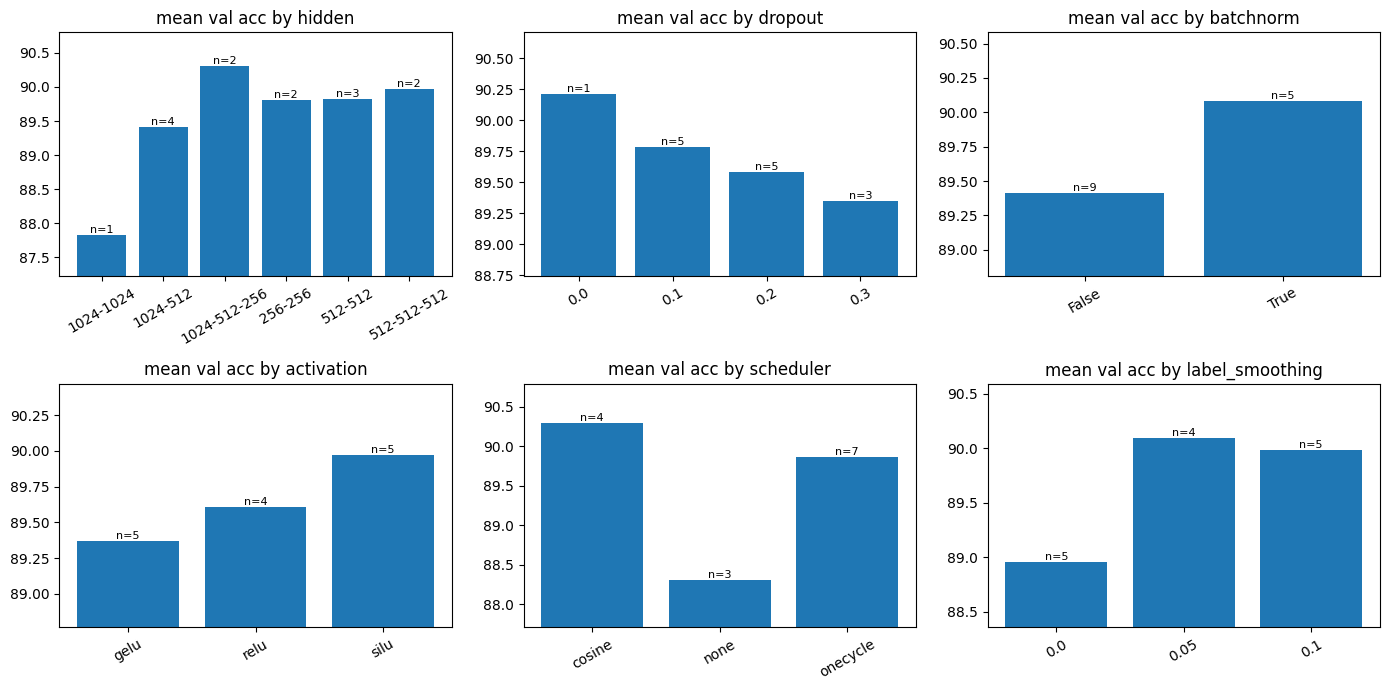

Spearman rank-correlation with validation accuracy:
log10_lr    0.165
log10_wd    0.056
Name: val_acc, dtype: float64

Caution: with only 14 trials these marginals are indicative, not conclusive (each bar averages over random values of all the other hyper-parameters).


In [ ]:
# ---- Which hyper-parameters actually matter?  (marginal analysis of the random search) ----
cat_cols = ["hidden", "dropout", "batchnorm", "activation", "scheduler", "label_smoothing"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    g = df3.groupby(col)["val_acc"].agg(["mean", "count"]).sort_index()
    ax.bar(g.index.astype(str), g["mean"] * 100, color="tab:blue")
    for x, (m_, c_) in enumerate(zip(g["mean"], g["count"])): ax.text(x, m_ * 100, f"n={c_}", ha="center", va="bottom", fontsize=8)
    lo, hi = g["mean"].min() * 100, g["mean"].max() * 100
    ax.set_ylim(lo - 0.6, hi + 0.5); ax.set_title(f"mean val acc by {col}"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

df3["log10_lr"] = np.log10(df3.lr); df3["log10_wd"] = np.log10(df3.weight_decay + 1e-8)
print("Spearman rank-correlation with validation accuracy:")
print(df3[["log10_lr", "log10_wd", "val_acc"]].corr(method="spearman")["val_acc"].drop("val_acc").round(3))
print("\nCaution: with only", len(df3), "trials these marginals are indicative, not conclusive "
      "(each bar averages over random values of all the other hyper-parameters).")

In [ ]:
# =====================================================================
# STAGE 4 — confirm the top-K random-search configs: several seeds, longer training
# =====================================================================
K = min(5, len(rs_results))
finalists = [c for c, _ in rs_results[:K]]
s4 = []
for i, cfg in enumerate(finalists):
    mean, std, accs = run_cfg(cfg, B["final_ep"], SEEDS, "stage4_mlp_confirm")
    f = flat(cfg)
    s4.append(dict(rs_rank=i + 1, val_acc_pct=round(mean * 100, 2), std_pct=round(std * 100, 2), hidden=f["hidden"],
                   dropout=f["dropout"], batchnorm=f["batchnorm"], activation=f["activation"], scheduler=f["scheduler"],
                   lr=round(f["lr"], 5), weight_decay=f"{f['weight_decay']:.2g}", label_smoothing=f["label_smoothing"], _i=i, _m=mean, _s=std))
df4 = pd.DataFrame(s4).sort_values("_m", ascending=False).reset_index(drop=True)
display(df4.drop(columns=["_i", "_m", "_s"]))

BEST_MLP_CFG = finalists[int(df4.iloc[0]._i)]
BEST_MLP_ACC = (float(df4.iloc[0]._m), float(df4.iloc[0]._s))
if len(df4) > 1:   # is the winner distinguishable from the runner-up, or just luckier?
    gap = (df4.iloc[0]._m - df4.iloc[1]._m) / (np.sqrt((df4.iloc[0]._s ** 2 + df4.iloc[1]._s ** 2) / len(SEEDS)) + 1e-9)
    print(f"winner-vs-runner-up gap = {gap:.1f} standard errors ->", "clear winner" if gap > 2 else "statistical tie (either config is fine)")
print("\nBEST MLP CONFIG:\n", {k: BEST_MLP_CFG[k] for k in ["hidden", "dropout", "batchnorm", "activation", "optimizer", "lr",
      "weight_decay", "scheduler", "label_smoothing", "batch_size"]})
print(f"val acc = {BEST_MLP_ACC[0]*100:.2f}% ± {BEST_MLP_ACC[1]*100:.2f}  ({B['final_ep']} epochs, {len(SEEDS)} seeds)")
elapsed("stage 4 done")

,rs_rank,val_acc_pct,std_pct,hidden,dropout,batchnorm,activation,scheduler,lr,weight_decay,label_smoothing
0,2,90.81,0.01,1024-512-256,0.2,True,gelu,cosine,0.14344,2.1e-06,0.10
1,1,90.75,0.18,1024-512,0.1,True,gelu,cosine,0.12877,0.00026,0.05
2,3,90.67,0.08,1024-512-256,0.1,False,gelu,cosine,0.05432,0,0.05
3,5,90.64,0.05,512-512,0.0,False,silu,onecycle,0.10996,0,0.05
4,4,90.57,0.05,256-256,0.1,True,silu,onecycle,0.09168,5.6e-05,0.10


winner-vs-runner-up gap = 0.5 standard errors -> statistical tie (either config is fine)

BEST MLP CONFIG:
 {'hidden': (1024, 512, 256), 'dropout': 0.2, 'batchnorm': True, 'activation': 'gelu', 'optimizer': 'sgd_mom', 'lr': 0.14344447363149085, 'weight_decay': 2.0906632330423255e-06, 'scheduler': 'cosine', 'label_smoothing': 0.1, 'batch_size': 128}
val acc = 90.81% ± 0.01  (15 epochs, 2 seeds)
[   6.7 min elapsed] stage 4 done


In [ ]:
# =====================================================================
# STAGE 5 — CNN family: random search + confirmation
# =====================================================================
CNN_CHANNELS = [(16, 32), (32, 64), (64, 128), (32, 64, 128)]
def sample_cnn_cfg(r):
    opt_name = pick(r, ["adam", "adamw", "sgd_mom"])
    return make_cfg(arch="cnn", optimizer=opt_name,
                    lr=float(best_lr_by_opt[opt_name] * 10 ** r.uniform(-0.3, 0.3)),   # reuse stage-1 knowledge
                    weight_decay=wd_sample(r, opt_name), batch_size=pick(r, [64, 128, 256]),
                    channels=pick(r, CNN_CHANNELS), fc=pick(r, [64, 128, 256]),
                    dropout=pick(r, [0.0, 0.2, 0.3, 0.5]), batchnorm=pick(r, [True, True, False]),   # BN twice as likely
                    scheduler=pick(r, ["cosine", "onecycle"]), flip=pick(r, [False, True]), shift=pick(r, [0, 2]),
                    label_smoothing=pick(r, [0.0, 0.05]))

rng_c = np.random.default_rng(SEED + 1)
cnn_results = []
for i in range(B["n_cnn"]):
    cfg = sample_cnn_cfg(rng_c)
    mean, _, _ = run_cfg(cfg, B["rs_ep"], [0], "stage5_cnn_rs")
    cnn_results.append((cfg, mean))
    f = flat(cfg)
    print(f"  trial {i+1:2d}/{B['n_cnn']}  {mean*100:6.2f}%  ch={f['channels']:10s} fc={cfg['fc']:3d} do={cfg['dropout']} bn={int(cfg['batchnorm'])} "
          f"{cfg['optimizer']:7s} lr={cfg['lr']:.4g} bs={cfg['batch_size']} flip={int(cfg['flip'])} shift={cfg['shift']}")
cnn_results.sort(key=lambda t: -t[1])
df5 = pd.DataFrame([{**flat(c), "val_acc": a} for c, a in cnn_results])
display(df5[["val_acc", "channels", "fc", "dropout", "batchnorm", "optimizer", "lr", "batch_size", "flip", "shift", "scheduler"]]
        .head(8).assign(val_acc=lambda d: (d.val_acc * 100).round(2)))

# confirm top-3 CNNs: multiple seeds, longer training
Kc = min(3, len(cnn_results))
cnn_final = []
for i, (cfg, _) in enumerate(cnn_results[:Kc]):
    mean, std, _ = run_cfg(cfg, B["final_ep"], SEEDS, "stage5_cnn_confirm")
    cnn_final.append((cfg, mean, std))
    print(f"  confirm #{i+1}: {mean*100:.2f}% ± {std*100:.2f}")
cnn_final.sort(key=lambda t: -t[1])
BEST_CNN_CFG, cnn_m, cnn_s = cnn_final[0]
print("\nBEST CNN CONFIG:", {k: BEST_CNN_CFG[k] for k in ["channels", "fc", "dropout", "batchnorm", "optimizer", "lr", "weight_decay",
      "scheduler", "batch_size", "flip", "shift", "label_smoothing"]})
elapsed("stage 5 done")

  trial  1/6   92.37%  ch=32-64      fc=256 do=0.2 bn=1 adamw   lr=0.0005324 bs=128 flip=0 shift=2
  trial  2/6   90.77%  ch=16-32      fc=256 do=0.2 bn=0 adamw   lr=0.0008953 bs=64 flip=0 shift=2
  trial  3/6   92.61%  ch=16-32      fc=256 do=0.2 bn=1 sgd_mom lr=0.0504 bs=128 flip=0 shift=2
  trial  4/6   90.25%  ch=64-128     fc= 64 do=0.5 bn=0 sgd_mom lr=0.1844 bs=128 flip=0 shift=0
  trial  5/6   93.19%  ch=64-128     fc=128 do=0.0 bn=1 sgd_mom lr=0.1073 bs=64 flip=0 shift=2
  trial  6/6   92.39%  ch=32-64      fc= 64 do=0.3 bn=1 sgd_mom lr=0.07627 bs=128 flip=0 shift=2


,val_acc,channels,fc,dropout,batchnorm,optimizer,lr,batch_size,flip,shift,scheduler
0,93.19,64-128,128,0.0,True,sgd_mom,0.107307,64,False,2,onecycle
1,92.61,16-32,256,0.2,True,sgd_mom,0.050402,128,False,2,cosine
2,92.39,32-64,64,0.3,True,sgd_mom,0.076274,128,False,2,onecycle
3,92.37,32-64,256,0.2,True,adamw,0.000532,128,False,2,onecycle
4,90.77,16-32,256,0.2,False,adamw,0.000895,64,False,2,cosine
5,90.25,64-128,64,0.5,False,sgd_mom,0.184383,128,False,0,cosine


  confirm #1: 93.88% ± 0.07
  confirm #2: 93.13% ± 0.06
  confirm #3: 92.84% ± 0.20

BEST CNN CONFIG: {'channels': (64, 128), 'fc': 128, 'dropout': 0.0, 'batchnorm': True, 'optimizer': 'sgd_mom', 'lr': 0.10730675315397956, 'weight_decay': 0.0, 'scheduler': 'onecycle', 'batch_size': 64, 'flip': False, 'shift': 2, 'label_smoothing': 0.0}
[  12.9 min elapsed] stage 5 done


{'MLP': '90.81% ± 0.01', 'CNN': '93.88% ± 0.07'} => overall winner: CNN


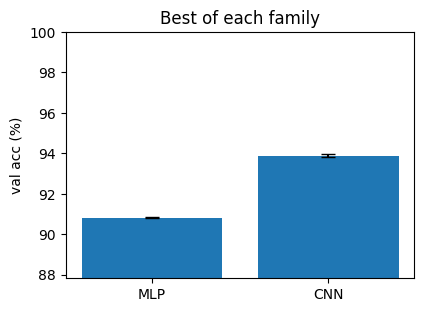

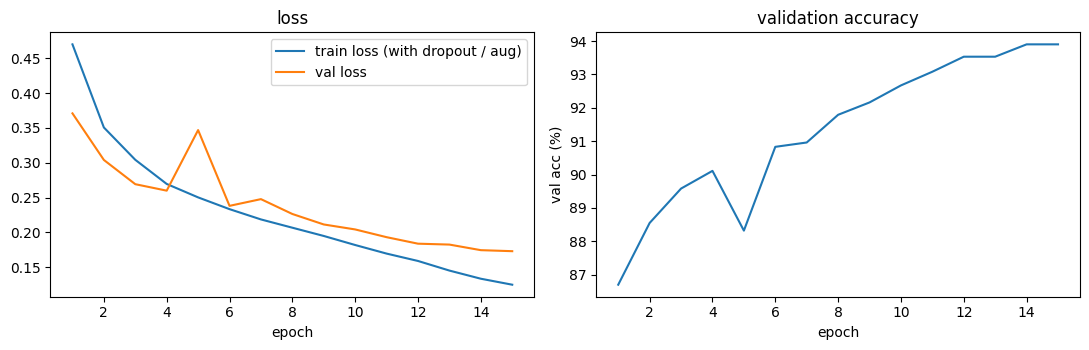

final val acc 93.90%, best epoch 14 (93.90%). If val loss rises while train loss keeps falling -> over-fitting (add regularisation / stop earlier); if both are still falling at the last epoch -> train longer.


In [ ]:
# =====================================================================
# MLP vs CNN: choose the overall winner (by VALIDATION accuracy)
# =====================================================================
cands = {"MLP": (BEST_MLP_CFG, *BEST_MLP_ACC), "CNN": (BEST_CNN_CFG, cnn_m, cnn_s)}
winner = max(cands, key=lambda k: cands[k][1])
BEST_CFG, BEST_EPOCHS = cands[winner][0], B["final_ep"]
print({k: f"{v[1]*100:.2f}% ± {v[2]*100:.2f}" for k, v in cands.items()}, "=> overall winner:", winner)

fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(list(cands), [v[1] * 100 for v in cands.values()], yerr=[v[2] * 100 for v in cands.values()], capsize=5)
ax.set_ylim(min(v[1] for v in cands.values()) * 100 - 3, 100); ax.set_ylabel("val acc (%)"); ax.set_title("Best of each family"); plt.show()

# ---- learning curves of the winner (diagnose under/over-fitting; still validation data only) ----
r = fit(BEST_CFG, DATA_TV, BEST_EPOCHS, seed=0, verbose=False)
h = r["history"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(h.epoch, h.train_loss, label="train loss (with dropout / aug)"); axs[0].plot(h.epoch, h.eval_loss, label="val loss")
axs[0].set_xlabel("epoch"); axs[0].legend(); axs[0].set_title("loss")
axs[1].plot(h.epoch, h.eval_acc * 100); axs[1].set_xlabel("epoch"); axs[1].set_ylabel("val acc (%)"); axs[1].set_title("validation accuracy")
plt.tight_layout(); plt.show()
print(f"final val acc {r['final_acc']*100:.2f}%, best epoch {r['best_epoch']} ({r['best_acc']*100:.2f}%). "
      f"If val loss rises while train loss keeps falling -> over-fitting (add regularisation / stop earlier); "
      f"if both are still falling at the last epoch -> train longer.")

## 6. Final evaluation on the test set (used once)

Now that all choices are frozen, we:
1. re-train the **original configuration** and the **tuned configuration** on the *full* 60,000 training images (train + validation, since the hyper-parameters are fixed),
2. evaluate on the 10,000 test images over several seeds,
3. add a small **ensemble** of the tuned models (average of softmax probabilities) as a further, nearly free improvement,
4. inspect per-class accuracy and the confusion matrix, and save the best hyper-parameters and weights.

,model,test_acc_pct,params
0,"original config (SGD 1e-3, 5 epochs)",64.99 ± 0.27,669706
1,tuned CNN (15 epochs),93.62 ± 0.10,879370
2,ensemble of 3 tuned models,94.02,2638110


improvement over the original configuration: +28.63 percentage points (error rate 35.0% -> 6.4%)


,class_name,accuracy_pct
6,Shirt,80.6
0,T-shirt/top,90.0
2,Pullover,91.5
4,Coat,92.0
3,Dress,94.3
9,Ankle boot,96.2
7,Sneaker,98.3
1,Trouser,99.1
5,Sandal,99.1
8,Bag,99.1


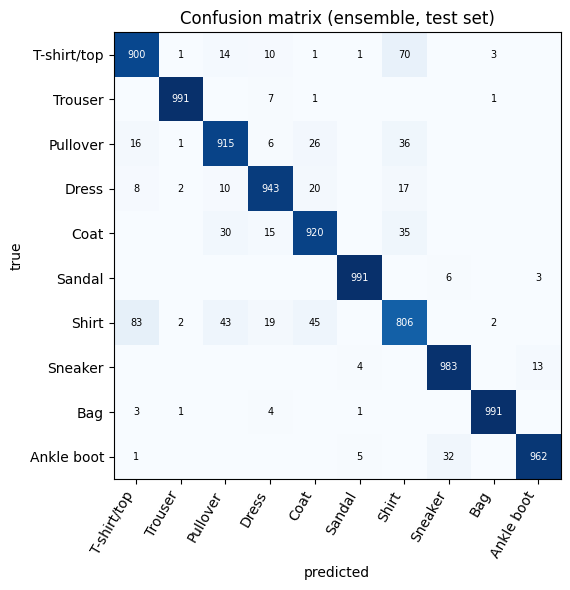

most frequent mistakes (count, true -> predicted):
    83  Shirt -> T-shirt/top
    70  T-shirt/top -> Shirt
    45  Shirt -> Coat
    43  Shirt -> Pullover
    36  Pullover -> Shirt

Saved best_model.pth (3.528 MB), best_hparams.json, tuning_log.csv
tuned model: 879,370 params, 3.36 MiB   (original: 669,706 params, 2.55 MiB)

=== PASTE THIS to rebuild the tuned model with the harness above ===
BEST_CFG = {'arch': 'cnn', 'hidden': [512, 512], 'channels': [64, 128], 'fc': 128, 'dropout': 0.0, 'batchnorm': True, 'activation': 'relu', 'optimizer': 'sgd_mom', 'lr': 0.10730675315397956, 'momentum': 0.9, 'weight_decay': 0.0, 'scheduler': 'onecycle', 'batch_size': 64, 'shuffle': True, 'normalize': True, 'flip': False, 'shift': 2, 'label_smoothing': 0.0} 
BEST_EPOCHS = 15
[  18.7 min elapsed] section 6 done


In [ ]:
# =====================================================================
# SECTION 6 — FINAL TEST-SET EVALUATION (the only place the tuned config meets the test set)
# =====================================================================
FINAL_SEEDS = list(range(B["final_seeds"]))
base_runs  = [fit(BASELINE, DATA_TEST, 5, seed=s) for s in FINAL_SEEDS]                       # original notebook config
tuned_runs = [fit(BEST_CFG, DATA_TEST, BEST_EPOCHS, seed=s, return_model=True) for s in FINAL_SEEDS]
base_acc  = np.array([r["final_acc"] for r in base_runs]) * 100
tuned_acc = np.array([r["final_acc"] for r in tuned_runs]) * 100

# ensemble: average the softmax probabilities of the seeds
tuned_models = [r["model"] for r in tuned_runs]
probs = sum(F.softmax(predict_logits(m, X_test, BEST_CFG["normalize"]), 1) for m in tuned_models) / len(tuned_models)
ens_pred = probs.argmax(1)
ens_acc = (ens_pred == y_test).float().mean().item() * 100

final_tbl = pd.DataFrame([
    dict(model="original config (SGD 1e-3, 5 epochs)", test_acc_pct=f"{base_acc.mean():.2f} ± {base_acc.std():.2f}", params=base_runs[0]["params"]),
    dict(model=f"tuned {BEST_CFG['arch'].upper()} ({BEST_EPOCHS} epochs)",    test_acc_pct=f"{tuned_acc.mean():.2f} ± {tuned_acc.std():.2f}", params=tuned_runs[0]["params"]),
    dict(model=f"ensemble of {len(tuned_models)} tuned models",               test_acc_pct=f"{ens_acc:.2f}", params=tuned_runs[0]["params"] * len(tuned_models)),
])
display(final_tbl)
print(f"improvement over the original configuration: +{tuned_acc.mean() - base_acc.mean():.2f} percentage points "
      f"(error rate {100-base_acc.mean():.1f}% -> {100-tuned_acc.mean():.1f}%)")

# ---- per-class accuracy and confusion matrix -------------------------
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def confusion(y_true, y_pred, K=10):
    return torch.bincount((y_true * K + y_pred).cpu(), minlength=K * K).reshape(K, K).numpy()
cm = confusion(y_test, ens_pred)
per_class = cm.diagonal() / cm.sum(1) * 100
display(pd.DataFrame(dict(class_name=CLASS_NAMES, accuracy_pct=per_class.round(1))).sort_values("accuracy_pct"))

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="w" if cm[i, j] > cm.max() / 2 else "k")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (ensemble, test set)"); plt.tight_layout(); plt.show()

off = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(10) if i != j]
print("most frequent mistakes (count, true -> predicted):")
for c, t, p in sorted(off, reverse=True)[:5]: print(f"  {c:4d}  {t} -> {p}")

# ---- save the best model + hyper-parameters; report size ----------
best_model = tuned_models[0]
torch.save(best_model.state_dict(), "best_model.pth")
cfg_json = {k: (list(v) if isinstance(v, tuple) else v) for k, v in BEST_CFG.items()}
with open("best_hparams.json", "w") as f: json.dump(dict(config=cfg_json, epochs=BEST_EPOCHS), f, indent=2)
pd.DataFrame(LOG).to_csv("tuning_log.csv", index=False)
rep_best = size_report(best_model, "tuned model")
print(f"\nSaved best_model.pth ({os.path.getsize('best_model.pth')/1e6:.3f} MB), best_hparams.json, tuning_log.csv")
print(f"tuned model: {rep_best['params']:,} params, {rep_best['tensor_MiB']:.2f} MiB   "
      f"(original: {rep['params']:,} params, {rep['tensor_MiB']:.2f} MiB)")
print("\n=== PASTE THIS to rebuild the tuned model with the harness above ===")
print("BEST_CFG =", cfg_json, "\nBEST_EPOCHS =", BEST_EPOCHS)
elapsed("section 6 done")

## 7. One-vs-All (OvA / One-vs-Rest) classification

**Idea.** Instead of one network with a 10-way softmax, train **K = 10 independent binary classifiers**. Classifier *k* answers
only *"is this image class k, or one of the other nine?"* (target `1` for class k, `0` otherwise), trained with the **binary
cross-entropy** loss on a single sigmoid output. At inference time all K classifiers score the image and we predict
`argmax_k score_k` (the sigmoid is monotonic, so arg-maxing the raw logits is equivalent to arg-maxing the probabilities).

**Things worth knowing / measuring below**

* **Class imbalance.** Every binary problem is ~10 % positive vs 90 % negative. `pos_weight = neg/pos ≈ 9` re-balances the loss; we *test* whether that helps.
* **Uncalibrated competition.** The K classifiers are trained independently, so their scores are not guaranteed to be comparable. Softmax trains the K scores to compete directly.
  Some images get **several** classifiers saying "yes" or **none**; the arg-max tie-break resolves this. We quantify how often this happens.
* **Cost.** K separate networks have ~K× the parameters and K× the training time of one network. A cheaper variant keeps *one shared network with K sigmoid outputs* (trained with BCE against the one-hot vector) – "OvA-shared".
* **Where OvA shines.** Linear/SVM-style base learners that only support binary problems (e.g. scikit-learn's `OneVsRestClassifier`). For neural nets with a softmax head it is mostly a pedagogical/robustness alternative.

We implement three OvA variants with the *same* code path and compare them with the softmax network:

| Name | Description |
|---|---|
| **OvA-separate** | 10 independent binary networks (the textbook method) |
| **OvA-shared** | 1 network, 10 sigmoid outputs, BCE loss |
| **OvA-linear** | 10 independent binary *linear* classifiers (= one-vs-rest logistic regression) – the classical baseline |

In [ ]:
# =====================================================================
# SECTION 7 — ONE-VS-ALL CLASSIFICATION (implemented from scratch)
# =====================================================================
K_CLASSES = 10

class OvAEnsemble(nn.Module):
    """K independent binary classifiers. forward() returns the K raw scores (logits) side by side -> shape [B, K].
    Class k's network only ever saw the question 'class k vs. everything else'."""
    def __init__(self, nets):
        super().__init__()
        self.nets = nn.ModuleList(nets)
    def forward(self, x):
        return torch.cat([n(x) for n in self.nets], dim=1)          # each n(x) has shape [B, 1]

def _train_binary(cfg, Xtr, ytr, out_dim, target_fn, pos_w, epochs, seed):
    """Train one network with a sigmoid / binary-cross-entropy objective. target_fn maps labels -> {0,1} targets [B, out_dim]."""
    set_seed(seed)
    net = build_model(cfg, out_dim=out_dim).to(device)
    opt = make_optimizer(net.parameters(), cfg)
    sch = make_scheduler(opt, cfg, math.ceil(len(ytr) / cfg["batch_size"]), epochs)
    for ep in range(epochs):
        net.train()
        for xb, yb in iterate_batches(Xtr, ytr, cfg["batch_size"], True):
            xb = prep(augment(xb, cfg["flip"], cfg["shift"]), cfg["normalize"])
            loss = F.binary_cross_entropy_with_logits(net(xb), target_fn(yb), pos_weight=pos_w)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            if sch is not None: sch.step()
    return net

def fit_ova(cfg, data, epochs, seed=0, mode="separate", pos_weight="auto"):
    """
    mode = "separate": K binary networks with out_dim=1 (true one-vs-all)
    mode = "shared"  : one network with K sigmoid outputs, trained on one-hot targets
    pos_weight = "auto": weight positives by (#negatives / #positives) of each binary problem (~9);  "none": plain BCE
    Returns (model whose forward gives [B,K] scores, accuracy of arg-max rule on data[2:4]).
    """
    Xtr, ytr, Xev, yev = data
    counts = torch.bincount(ytr.cpu(), minlength=K_CLASSES).float()
    ratio = ((len(ytr) - counts) / counts).to(device)               # neg/pos per class, ~9.0
    if mode == "separate":
        nets = []
        for k in range(K_CLASSES):
            pw = ratio[k:k + 1] if pos_weight == "auto" else None
            tgt = lambda yb, k=k: (yb == k).float().unsqueeze(1)    # 1 for class k, 0 for the other nine
            nets.append(_train_binary(cfg, Xtr, ytr, 1, tgt, pw, epochs, seed * 100 + k))
        m = OvAEnsemble(nets)
    else:
        pw = ratio if pos_weight == "auto" else None
        tgt = lambda yb: torch.zeros(len(yb), K_CLASSES, device=yb.device).scatter_(1, yb[:, None], 1.0)
        m = _train_binary(cfg, Xtr, ytr, K_CLASSES, tgt, pw, epochs, seed)
    acc = (predict_logits(m, Xev, cfg["normalize"]).argmax(1) == yev).float().mean().item()
    return m, acc

# ---- sanity check: the K binary heads really are separate networks ---
_m, _a = fit_ova(make_cfg(hidden=(64,), optimizer="adam", lr=1e-3), DATA_TV, 1, mode="separate")
print(f"OvA-separate smoke test: {len(_m.nets)} networks, {sum(p.numel() for p in _m.parameters()):,} params, val acc {_a*100:.1f}%")
del _m

OvA-separate smoke test: 10 networks, 503,050 params, val acc 84.7%


### 7.1 Tuning the one-vs-all classifiers (validation set only)

The search space is deliberately small because one OvA-separate trial = 10 trainings:

1. **backbone size** (linear / small / the best MLP found in Section 5) × **loss weighting** (`pos_weight` none vs auto) – at the best MLP's optimizer & learning rate;
2. **learning-rate multiplier** (×0.5, ×1, ×2) for the best variant of each mode;
3. the **shared-head** variant on the best backbone.

In [ ]:
# =====================================================================
# 7.1  OvA TUNING
# =====================================================================
ova_base = dict(BEST_MLP_CFG)                                 # inherit optimizer / lr / schedule / regularisation of the best MLP
variants = {"linear (784->1)":   dict(hidden=()),
            "small (784-128-1)": dict(hidden=(128,)),
            "best-MLP backbone": dict(hidden=BEST_MLP_CFG["hidden"])}
ova_rows, ova_cache = [], {}

def ova_trial(vname, mode, pw, mult):
    key = (vname, mode, pw, mult)
    if key not in ova_cache:
        cfg = {**ova_base, **variants[vname], "lr": ova_base["lr"] * mult}
        t0 = time.time(); m, acc = fit_ova(cfg, DATA_TV, B["ova_ep"], seed=0, mode=mode, pos_weight=pw)
        ova_cache[key] = acc
        ova_rows.append(dict(mode=mode, backbone=vname, pos_weight=pw, lr_mult=mult, val_acc_pct=round(acc * 100, 2),
                             params=sum(p.numel() for p in m.parameters()), seconds=round(time.time() - t0, 1)))
        print(f"  {mode:9s} {vname:18s} pos_weight={pw:4s} lr x{mult:<4g} -> {acc*100:6.2f}%  ({time.time()-t0:.0f}s)")
        del m
    return ova_cache[key]

# (1) backbone x pos_weight for the separate (textbook) variant
for vname in variants:
    for pw in ["none", "auto"]:
        ova_trial(vname, "separate", pw, 1.0)
# (3) shared-head variant on the best backbone
for pw in ["none", "auto"]:
    ova_trial("best-MLP backbone", "shared", pw, 1.0)
# (2) lr sweep around the best setting of each mode
def best_at_base_lr(mode, include=None, exclude=None):
    c = {k: v for k, v in ova_cache.items() if k[1] == mode and k[3] == 1.0 and (include is None or k[0] == include) and (exclude is None or k[0] != exclude)}
    return max(c, key=c.get)
for mode, inc, exc in [("separate", None, "linear (784->1)"), ("shared", None, None), ("separate", "linear (784->1)", None)]:
    v, _, pw, _ = best_at_base_lr(mode, inc, exc)
    for mu in [0.5, 2.0]: ova_trial(v, mode, pw, mu)

df_ova = pd.DataFrame(ova_rows).sort_values("val_acc_pct", ascending=False).reset_index(drop=True)
display(df_ova)

def best_setting(mode, include=None, exclude=None):
    """Best (backbone, mode, pos_weight, lr_mult) key found so far for a mode, optionally filtering backbones."""
    c = {k: v for k, v in ova_cache.items() if k[1] == mode and (include is None or k[0] == include) and (exclude is None or k[0] != exclude)}
    return max(c, key=c.get)
OVA_SEP = best_setting("separate", exclude="linear (784->1)")      # textbook OvA with non-linear binary nets
OVA_SHR = best_setting("shared")
OVA_LIN = best_setting("separate", include="linear (784->1)")      # classical one-vs-rest logistic regression
print("selected  OvA-separate:", OVA_SEP, "\n          OvA-shared  :", OVA_SHR, "\n          OvA-linear  :", OVA_LIN)
elapsed("OvA tuning done")

  separate  linear (784->1)    pos_weight=none lr x1    ->  84.92%  (25s)
  separate  linear (784->1)    pos_weight=auto lr x1    ->  82.95%  (27s)
  separate  small (784-128-1)  pos_weight=none lr x1    ->  89.56%  (37s)
  separate  small (784-128-1)  pos_weight=auto lr x1    ->  89.18%  (39s)
  separate  best-MLP backbone  pos_weight=none lr x1    ->  90.40%  (58s)
  separate  best-MLP backbone  pos_weight=auto lr x1    ->  89.48%  (61s)
  shared    best-MLP backbone  pos_weight=none lr x1    ->  90.18%  (6s)
  shared    best-MLP backbone  pos_weight=auto lr x1    ->  89.67%  (6s)
  separate  best-MLP backbone  pos_weight=none lr x0.5  ->  90.56%  (58s)
  separate  best-MLP backbone  pos_weight=none lr x2    ->  90.27%  (58s)
  shared    best-MLP backbone  pos_weight=none lr x0.5  ->  89.84%  (6s)
  shared    best-MLP backbone  pos_weight=none lr x2    ->  90.21%  (6s)
  separate  linear (784->1)    pos_weight=none lr x0.5  ->  85.07%  (25s)
  separate  linear (784->1)    pos_weight=

,mode,backbone,pos_weight,lr_mult,val_acc_pct,params,seconds
0,separate,best-MLP backbone,none,0.5,90.56,14638090,58.4
1,separate,best-MLP backbone,none,1.0,90.40,14638090,58.1
2,separate,best-MLP backbone,none,2.0,90.27,14638090,57.7
3,shared,best-MLP backbone,none,2.0,90.21,1466122,5.6
4,shared,best-MLP backbone,none,1.0,90.18,1466122,6.2
5,shared,best-MLP backbone,none,0.5,89.84,1466122,6.2
6,shared,best-MLP backbone,auto,1.0,89.67,1466122,5.9
7,separate,small (784-128-1),none,1.0,89.56,1008650,37.1
8,separate,best-MLP backbone,auto,1.0,89.48,14638090,60.7
9,separate,small (784-128-1),auto,1.0,89.18,1008650,38.7


selected  OvA-separate: ('best-MLP backbone', 'separate', 'none', 0.5) 
          OvA-shared  : ('best-MLP backbone', 'shared', 'none', 2.0) 
          OvA-linear  : ('linear (784->1)', 'separate', 'none', 0.5)
[  26.1 min elapsed] OvA tuning done


### 7.2 Final comparison on the test set: softmax vs One-vs-All

All methods are trained on the full 60k training set for the same number of epochs as the tuned softmax model and evaluated on the test set.
The **softmax MLP uses the same backbone as OvA** (`BEST_MLP_CFG`), so the comparison isolates the *loss / decision rule*
(10-way softmax vs. ten sigmoid/binary problems), not the architecture.

In [ ]:
# =====================================================================
# 7.2  TEST-SET COMPARISON:  softmax  vs  OvA-separate / OvA-shared / OvA-linear
# =====================================================================
OVA_SEEDS = list(range(B["ova_seeds"]))
EP = B["final_ep"]
def ova_cfg(setting):
    v, mode, pw, mu = setting
    return {**ova_base, **variants[v], "lr": ova_base["lr"] * mu}, mode, pw

results, models_keep = {}, {}
# (a) softmax baseline with the same backbone
runs = [fit(BEST_MLP_CFG, DATA_TEST, EP, seed=s, return_model=True) for s in OVA_SEEDS]
results["softmax (same backbone)"] = ([r["final_acc"] * 100 for r in runs], runs[0]["params"])
models_keep["softmax (same backbone)"] = runs[0]["model"]
# (b) the three OvA variants
for name, setting in [("OvA-separate (10 nets)", OVA_SEP), ("OvA-shared (1 net, 10 sigmoids)", OVA_SHR), ("OvA-linear (10 binary linear)", OVA_LIN)]:
    cfg, mode, pw = ova_cfg(setting)
    accs, last = [], None
    for s in OVA_SEEDS:
        m, a = fit_ova(cfg, DATA_TEST, EP, seed=s, mode=mode, pos_weight=pw)
        accs.append(a * 100)
        if last is None: last = m
    results[name] = (accs, sum(p.numel() for p in last.parameters()))
    models_keep[name] = last
    print(f"  {name:34s} {np.mean(accs):.2f}% ± {np.std(accs):.2f}")

rows = []
for name, (accs, n_par) in results.items():
    rows.append(dict(method=name, test_acc_pct=f"{np.mean(accs):.2f} ± {np.std(accs):.2f}", params=f"{n_par:,}",
                     size_MiB_fp32=round(n_par * 4 / 2**20, 2)))
display(pd.DataFrame(rows))
print(f"(for reference, the best overall model from Section 6: {tuned_acc.mean():.2f}% ± {tuned_acc.std():.2f}, {tuned_runs[0]['params']:,} params)")
print("Mean +- std over", len(OVA_SEEDS), "seed(s). With 1 seed there is no spread estimate; differences < ~0.3 % are within test-set noise.")

  OvA-separate (10 nets)             90.95% ± 0.15
  OvA-shared (1 net, 10 sigmoids)    90.61% ± 0.09
  OvA-linear (10 binary linear)      84.06% ± 0.01


,method,test_acc_pct,params,size_MiB_fp32
0,softmax (same backbone),90.60 ± 0.04,"1,466,122",5.59
1,OvA-separate (10 nets),90.95 ± 0.15,"14,638,090",55.84
2,"OvA-shared (1 net, 10 sigmoids)",90.61 ± 0.09,"1,466,122",5.59
3,OvA-linear (10 binary linear),84.06 ± 0.01,"7,850",0.03


(for reference, the best overall model from Section 6: 93.62% ± 0.10, 879,370 params)
Mean +- std over 2 seed(s). With 1 seed there is no spread estimate; differences < ~0.3 % are within test-set noise.


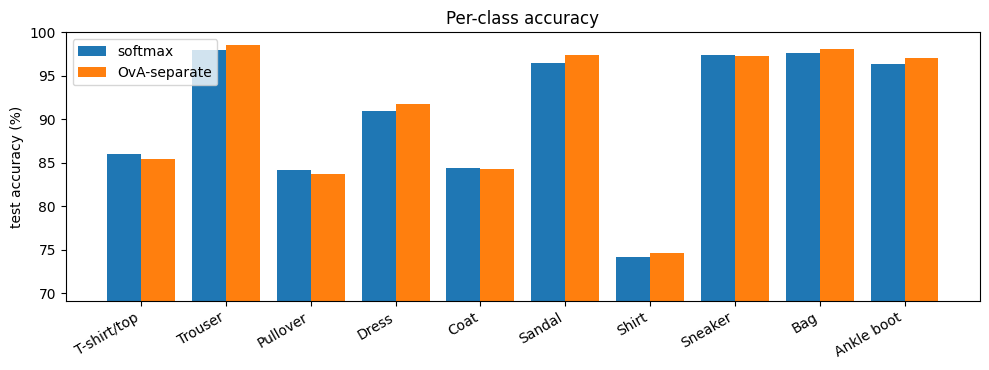

,situation,share_pct,arg_max_accuracy_pct
0,no classifier fires,3.9,50.8
1,exactly one fires,93.1,93.6
2,>= 2 classifiers fire,3.1,55.7


Where the ten binary classifiers disagree, the arg-max tie-break is what decides the label; compare the accuracy in these rows with the 'exactly one fires' row.
(With pos_weight='auto' the 0.5 threshold is biased towards firing, so ambiguity is expected to be higher.)

softmax and OvA-separate predict the same class for 96.3% of test images.
[  35.6 min elapsed] section 7 done


In [ ]:
# =====================================================================
# 7.3  OvA ANALYSIS: per-class accuracy, and how often do the K binary classifiers disagree?
# =====================================================================
soft_m, ova_m = models_keep["softmax (same backbone)"], models_keep["OvA-separate (10 nets)"]
nrm = BEST_MLP_CFG["normalize"]
pred_soft = predict_logits(soft_m, X_test, nrm).argmax(1)
logit_ova = predict_logits(ova_m,  X_test, nrm)
pred_ova  = logit_ova.argmax(1)

# ---- per-class accuracy, softmax vs OvA ------------------------------
acc_soft = confusion(y_test, pred_soft).diagonal() / 1000 * 100          # 1000 test images per class
acc_ova  = confusion(y_test, pred_ova).diagonal()  / 1000 * 100
fig, ax = plt.subplots(figsize=(10, 3.8)); w = 0.4; xs = np.arange(10)
ax.bar(xs - w / 2, acc_soft, w, label="softmax"); ax.bar(xs + w / 2, acc_ova, w, label="OvA-separate")
ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right"); ax.set_ylabel("test accuracy (%)")
ax.set_ylim(min(acc_soft.min(), acc_ova.min()) - 5, 100); ax.legend(); ax.set_title("Per-class accuracy"); plt.tight_layout(); plt.show()

# ---- ambiguity of the OvA decision rule --------------------------------
# A classifier "fires" if its sigmoid output > 0.5.  Ideally exactly one fires per image.
n_fire = (torch.sigmoid(logit_ova) > 0.5).sum(1)
rows = []
for label, mask in [("no classifier fires", n_fire == 0), ("exactly one fires", n_fire == 1), (">= 2 classifiers fire", n_fire >= 2)]:
    cnt = int(mask.sum())
    rows.append(dict(situation=label, share_pct=round(cnt / len(y_test) * 100, 1),
                     arg_max_accuracy_pct=round((pred_ova[mask] == y_test[mask]).float().mean().item() * 100, 1) if cnt else float("nan")))
display(pd.DataFrame(rows))
print("Where the ten binary classifiers disagree, the arg-max tie-break is what decides the label; compare the accuracy in these "
      "rows with the 'exactly one fires' row.\n(With pos_weight='auto' the 0.5 threshold is biased towards firing, so ambiguity is expected to be higher.)")

agree = (pred_soft == pred_ova).float().mean().item() * 100
print(f"\nsoftmax and OvA-separate predict the same class for {agree:.1f}% of test images.")
elapsed("section 7 done")

## 8. How to read the results and what to do next

* **Section 1** gives the exact size of the final model: **669,706 parameters ≈ 2.55 MiB (2.68 MB) in float32**.
* **Section 4/5** tell you which changes matter. Typical outcome on FashionMNIST (check against *your* numbers): fixing the optimizer/lr and training longer
  gives the largest jump for the MLP (low-90s% is about the ceiling for an MLP); regularisation adds a few tenths; moving to a small CNN with batch-norm
  (and flip/shift augmentation) usually adds a few more points. Anything within ~0.3 % is noise.
* **Section 6** prints the tuned hyper-parameters (`BEST_CFG`) and writes `best_hparams.json`, `best_model.pth` and `tuning_log.csv` (every run, for your own analysis).
* **Section 7** compares One-vs-All against softmax. Expect OvA to be roughly on par or slightly worse than softmax with the same backbone, at ~10× the parameters for OvA-separate.
* **Further ideas** (not run here): wider search with a library such as Optuna / Ray Tune (successive-halving to stop bad trials early), longer training with SWA/EMA of weights, mixup/cutout augmentation,
  a ResNet-style CNN, and averaging more ensemble members.

**To re-run with different effort**, change `BUDGET` in Section 0 (`"smoke"`, `"quick"`, `"standard"`) and run all cells below the original notebook again.